# 03 — Exploratory Data Analysis — Fisher's Iris

**Stage 3 of the Tier A pipeline** (`DOCS/STRUCTURE.md`). Hypothesis-driven, one section per
issue-tree branch. Every chart carries an **Action Title** and a written **So What / Implication**.
No orphan charts.

Stages 1–2 established what the *instrument* is worth. This notebook asks what the *measurements*
are worth, and it has one job: locate the signal precisely enough that the modelling notebook is
testing a hypothesis rather than fishing.

The issue tree from `IMPLEMENTATION_PLAN.md` §0.3 splits the four features into two branches, and
the whole of EDA is a test of which one carries the information:

- **Branch B — sepal morphology** (`SepalLengthCm`, `SepalWidthCm`)
- **Branch C — petal morphology** (`PetalLengthCm`, `PetalWidthCm`)

`DOCS/Iris_Dataset_Analysis.md` §2 predicts the answer — *"petal length and petal width... these two
columns alone nearly solve the classification problem"* — and §2 also predicts where it breaks:
*versicolor* and *virginica* overlap. Both predictions are tested here rather than repeated.

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SRC_NAME = "Iris.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS = ROOT / "reports", ROOT / "reports" / "figures"
for d in (RAW, PROC, REPORTS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# ---- DESIGN.md palette (DOCS/DESIGN.md section 2) - defined inline, never re-picked -------
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER, SLATE, GREY, GRID = "#00A9F4", "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
# Fixed semantic mapping for this project (IMPLEMENTATION_PLAN section 7.2)
SPECIES_COLOR = {"Iris-setosa": BLUE, "Iris-versicolor": TEAL, "Iris-virginica": CYAN}
SPECIES_SHORT = {"Iris-setosa": "setosa", "Iris-versicolor": "versicolor", "Iris-virginica": "virginica"}
SPECIES_ORDER = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]


def apply_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "font.size": 9.5,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.edgecolor": SLATE,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11.5,
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 190,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.25,
    })


apply_style()
MEASUREMENTS = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
TARGET = "Species"


def action_title(ax, title, sub=None):
    """DESIGN.md section 1.3 - titles state the insight, flush-left."""
    ax.set_title(title, loc="left", pad=26 if sub else 12)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8.5, color=SLATE,
                va="bottom", ha="left")


def save_fig(fig, name):
    p = FIGS / f"{name}.png"
    fig.savefig(p)
    print(f"saved {p.relative_to(ROOT)}")


import seaborn as sns
from scipy import stats

df = pd.read_parquet(PROC / "iris_clean.parquet").reset_index()
df["species"] = df[TARGET].astype(str).map(SPECIES_SHORT)
y = np.asarray(df[TARGET].astype(str))
KEY = {}   # every number the report quotes gets written to reports/_key_figures.json

print(f"loaded {df.shape[0]} specimens x {len(MEASUREMENTS)} measurements")
print(f"class balance: {df['species'].value_counts().to_dict()}")

loaded 150 specimens x 4 measurements
class balance: {'setosa': 50, 'versicolor': 50, 'virginica': 50}


## 3.1 Profile and the baseline every model must beat

Automated profiling (`ydata-profiling`) is optional in this project — on four numeric columns it
adds nothing a describe-plus-shape panel does not, and it is not in the pinned requirements, so the
manual panel below is the primary artefact rather than a fallback.

The number that matters here is the **majority-class baseline: 33.3%**. Perfect balance is why
accuracy is a legitimate headline metric on this dataset — unlike the imbalanced projects in this
portfolio, there is no accuracy trap to avoid. It is also why the baseline is so low, which sets a
generous-looking bar that every model clears easily. That is exactly the trap this project is about:
*clearing a low bar is not the same as being distinguishable from the model next to you.*

In [2]:
profile = df[MEASUREMENTS].describe().T[["mean", "50%", "std", "min", "max"]]
profile.columns = ["mean", "median", "sd", "min", "max"]
profile["IQR"] = df[MEASUREMENTS].quantile(.75) - df[MEASUREMENTS].quantile(.25)
profile["skew"] = df[MEASUREMENTS].skew()
profile["kurtosis"] = df[MEASUREMENTS].kurtosis()
profile["cv_pct"] = (profile["sd"] / profile["mean"] * 100)
profile = profile.round(3)

KEY["majority_baseline"] = float(df[TARGET].value_counts(normalize=True).max())
print(f"majority-class baseline: {KEY['majority_baseline']:.1%}\n")
profile

majority-class baseline: 33.3%



,mean,median,sd,min,max,IQR,skew,kurtosis,cv_pct
SepalLengthCm,5.843,5.80,0.828,4.3,7.9,1.3,0.315,-0.552,14.171
SepalWidthCm,3.054,3.00,0.434,2.0,4.4,0.5,0.334,0.291,14.198
PetalLengthCm,3.759,4.35,1.764,1.0,6.9,3.5,-0.274,-1.402,46.943
PetalWidthCm,1.199,1.30,0.763,0.1,2.5,1.5,-0.105,-1.340,63.667


**So What:** the petal features carry **3–4.5× the relative spread** of the sepal features
(`PetalWidthCm` CV = 64% and `PetalLengthCm` 47%, against 14% for both sepal features). Both petal features are also mildly bimodal
rather than bell-shaped — visible in the negative kurtosis — which is the statistical signature of
two or more separated groups sitting inside one column.

**Implication:** `SepalWidthCm` is nearly constant across the whole file. A feature that barely
varies overall cannot separate groups, so Branch B is already under suspicion before a single
group comparison is run.

## 3.2 Per-species summaries — where the separation actually is

`DOCS/Iris_Dataset_Analysis.md` §5 calls this *"the single most useful descriptive step, since it
directly shows separability."* Agreed — and the useful form is not the means but the **ranges**,
because separability is about whether the groups' values *overlap*, not whether their averages
differ.

In [3]:
by_species = (df.groupby("species")[MEASUREMENTS]
                .agg(["mean", "std", "min", "max"]).round(2))
by_species = by_species.reindex([SPECIES_SHORT[s] for s in SPECIES_ORDER])
by_species

SepalLengthCm                 SepalWidthCm                 PetalLengthCm                 PetalWidthCm                
                    mean   std  min  max         mean   std  min  max          mean   std  min  max         mean   std  min  max
species                                                                                                                         
setosa              5.01  0.35  4.3  5.8         3.42  0.38  2.3  4.4          1.46  0.17  1.0  1.9         0.24  0.11  0.1  0.6
versicolor          5.94  0.52  4.9  7.0         2.77  0.31  2.0  3.4          4.26  0.47  3.0  5.1         1.33  0.20  1.0  1.8
virginica           6.59  0.64  4.9  7.9         2.97  0.32  2.2  3.8          5.55  0.55  4.5  6.9         2.03  0.27  1.4  2.5

In [4]:
# Do the observed ranges of the three species overlap, feature by feature?
gaps = []
for col in MEASUREMENTS:
    rng_by_sp = {sp: (df.loc[df.species == sp, col].min(), df.loc[df.species == sp, col].max())
                 for sp in ["setosa", "versicolor", "virginica"]}
    for a, b in [("setosa", "versicolor"), ("versicolor", "virginica"), ("setosa", "virginica")]:
        lo_a, hi_a = rng_by_sp[a]
        lo_b, hi_b = rng_by_sp[b]
        gap = max(lo_a, lo_b) - min(hi_a, hi_b)   # >0 means a clean gap, no overlap at all
        gaps.append({"feature": col, "pair": f"{a} vs {b}",
                     f"{a}_range": f"{lo_a}-{hi_a}", f"{b}_range": f"{lo_b}-{hi_b}",
                     "gap_cm": round(gap, 2), "ranges_disjoint": gap > 0})

gap_df = pd.DataFrame(gaps)
clean = gap_df[gap_df.ranges_disjoint]
print("Feature/pair combinations where the two species' observed ranges DO NOT overlap at all:\n")
print(clean[["feature", "pair", "gap_cm"]].to_string(index=False))
print()
print(f"{len(clean)} of {len(gap_df)} feature-pair combinations are perfectly separated.")
print("Every one of them involves setosa. None involve versicolor vs virginica.")
KEY["n_disjoint_combinations"] = int(len(clean))

Feature/pair combinations where the two species' observed ranges DO NOT overlap at all:

      feature                 pair  gap_cm
PetalLengthCm setosa vs versicolor     1.1
PetalLengthCm  setosa vs virginica     2.6
 PetalWidthCm setosa vs versicolor     0.4
 PetalWidthCm  setosa vs virginica     0.8

4 of 12 feature-pair combinations are perfectly separated.
Every one of them involves setosa. None involve versicolor vs virginica.


**So What:** on `PetalLengthCm` there is a **1.1 cm empty corridor** between the largest setosa
petal (1.9 cm) and the smallest versicolor petal (3.0 cm) — no specimen of any species falls in it.
`PetalWidthCm` has a 0.4 cm corridor. Setosa is not merely *easy*; it is separated by a region the
data does not enter.

**Implication:** the three-class problem is really **one trivial problem and one hard problem**.
Any model will solve setosa perfectly, so all reported accuracy differences between models are
being decided entirely on the versicolor/virginica boundary — roughly a third of the file. That
observation is what makes the small-sample argument in Notebook 05 bite: the effective sample size
for model comparison is not 150.

saved reports\figures\ex03_distributions.png


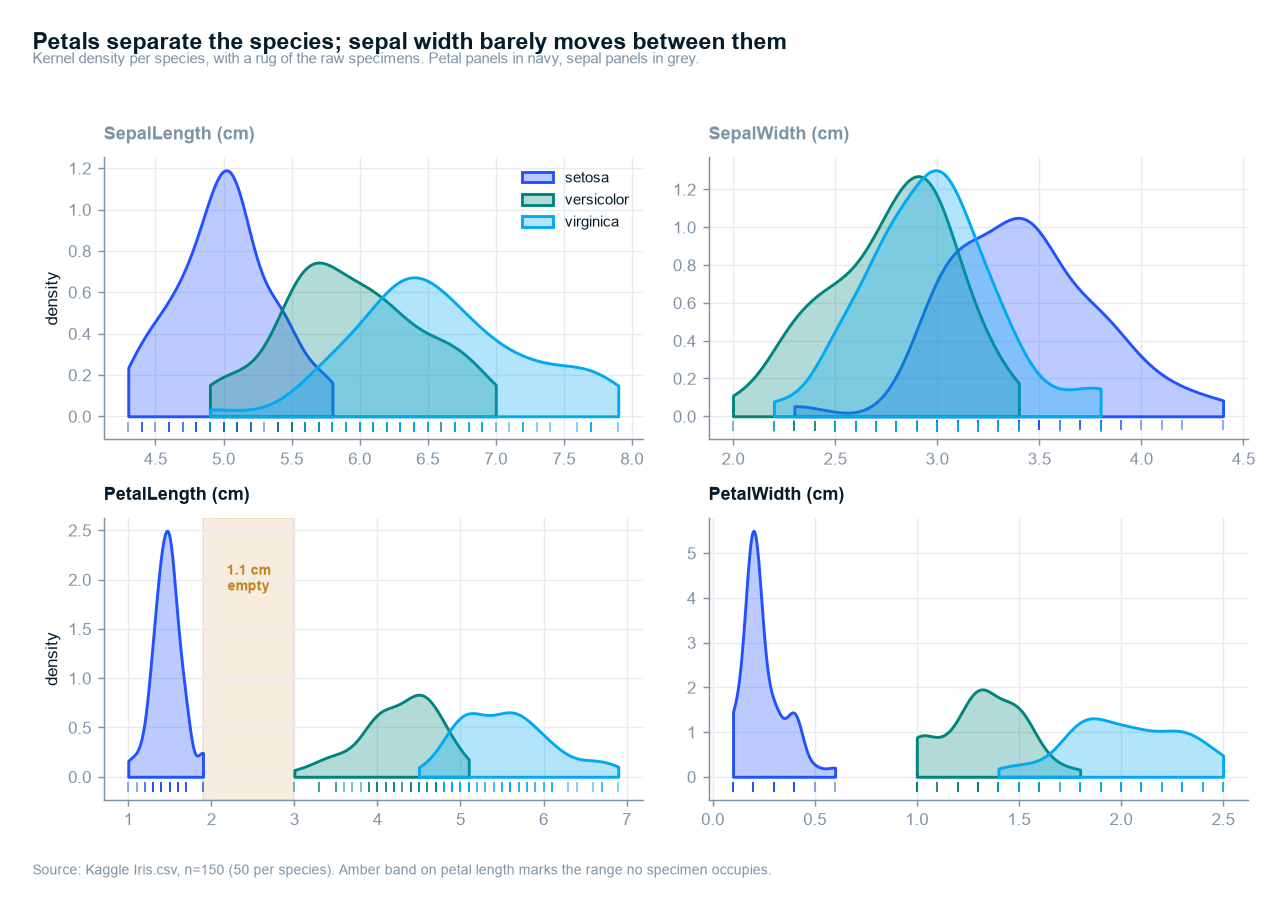

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 6.0))
for ax, col in zip(axes.ravel(), MEASUREMENTS):
    for sp in SPECIES_ORDER:
        vals = df.loc[df[TARGET].astype(str) == sp, col]
        sns.kdeplot(x=vals, ax=ax, fill=True, alpha=.30, linewidth=1.6,
                    color=SPECIES_COLOR[sp], label=SPECIES_SHORT[sp], bw_adjust=.85, cut=0)
        ax.plot(vals, np.full(len(vals), -0.04 * ax.get_ylim()[1]), "|",
                color=SPECIES_COLOR[sp], alpha=.55, markersize=5)
    is_petal = col.startswith("Petal")
    ax.set_title(f"{col[:-2]} (cm)", loc="left", fontsize=10,
                 color=NAVY if is_petal else SLATE)
    ax.set_xlabel(""); ax.set_ylabel("density" if col in MEASUREMENTS[::2] else "")

# annotate the empty corridor on petal length
ax_pl = axes.ravel()[2]
ax_pl.axvspan(1.9, 3.0, color=AMBER, alpha=.14, zorder=0)
ax_pl.text(2.45, ax_pl.get_ylim()[1] * .72, "1.1 cm\nempty", ha="center", fontsize=8,
           color=AMBER, fontweight="bold")

axes[0, 0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Petals separate the species; sepal width barely moves between them",
             x=0.005, y=1.045, ha="left", fontsize=12.5, fontweight="bold", color=NAVY)
fig.text(0.005, 1.005, "Kernel density per species, with a rug of the raw specimens. "
                       "Petal panels in navy, sepal panels in grey.",
         ha="left", fontsize=8.5, color=SLATE)
fig.text(0.005, -0.035, "Source: Kaggle Iris.csv, n=150 (50 per species). Amber band on petal "
                        "length marks the range no specimen occupies.",
         ha="left", fontsize=7.5, color=SLATE)
fig.tight_layout()
save_fig(fig, "ex03_distributions")
plt.show()

## 3.3 Quantifying the overlap instead of eyeballing it

`DOCS/Iris_Dataset_Analysis.md` §5 asks for the versicolor/virginica overlap to be assessed
*"quantitatively rather than just visually."* Two measures are computed per feature per species
pair:

- **Overlap coefficient (OVL)** — the shared area under the two density curves. 0 = perfectly
  separated, 1 = identical distributions. Directly interpretable as *"the fraction of the
  distribution the two species have in common."*
- **Bhattacharyya distance** — a distributional distance that grows without bound as separation
  increases, so it discriminates well among already-separated pairs where OVL saturates at 0.

Reporting **separation = 1 − OVL** puts everything on one 0–1 scale where higher is better.

In [6]:
def overlap_coefficient(a, b, n_grid=1000):
    lo = min(a.min(), b.min()) - 0.5
    hi = max(a.max(), b.max()) + 0.5
    grid = np.linspace(lo, hi, n_grid)
    fa = stats.gaussian_kde(a, bw_method="scott")(grid)
    fb = stats.gaussian_kde(b, bw_method="scott")(grid)
    return float(np.trapezoid(np.minimum(fa, fb), grid))


def bhattacharyya(a, b, n_grid=1000):
    lo = min(a.min(), b.min()) - 0.5
    hi = max(a.max(), b.max()) + 0.5
    grid = np.linspace(lo, hi, n_grid)
    fa = stats.gaussian_kde(a, bw_method="scott")(grid)
    fb = stats.gaussian_kde(b, bw_method="scott")(grid)
    bc = float(np.trapezoid(np.sqrt(fa * fb), grid))
    return -np.log(max(bc, 1e-12))


PAIRS = [("setosa", "versicolor"), ("setosa", "virginica"), ("versicolor", "virginica")]
rows = []
for col in MEASUREMENTS:
    for a, b in PAIRS:
        va = df.loc[df.species == a, col].to_numpy()
        vb = df.loc[df.species == b, col].to_numpy()
        ovl = overlap_coefficient(va, vb)
        rows.append({"feature": col, "pair": f"{a} vs {b}",
                     "overlap_OVL": round(ovl, 3), "separation_1_minus_OVL": round(1 - ovl, 3),
                     "bhattacharyya": round(bhattacharyya(va, vb), 2)})

sep = pd.DataFrame(rows)
sep.to_csv(REPORTS / "_separation.csv", index=False)
sep.pivot(index="feature", columns="pair", values="separation_1_minus_OVL").loc[MEASUREMENTS]

pair,setosa vs versicolor,setosa vs virginica,versicolor vs virginica
feature,,,
SepalLengthCm,0.676,0.874,0.390
SepalWidthCm,0.618,0.461,0.195
PetalLengthCm,1.000,1.000,0.776
PetalWidthCm,1.000,1.000,0.836


saved reports\figures\ex04_separation.png


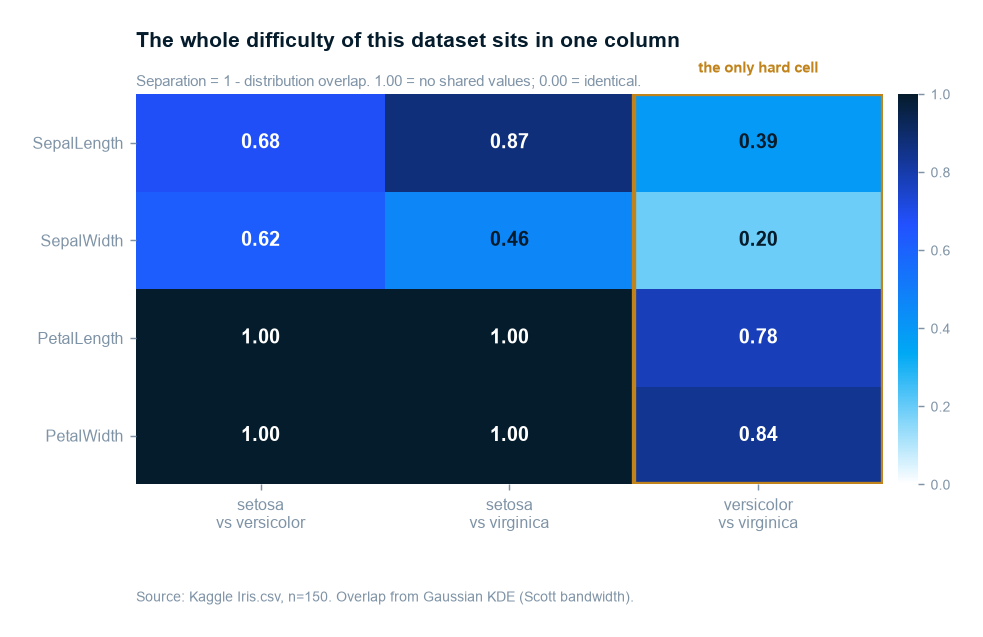

In [7]:
pivot = sep.pivot(index="feature", columns="pair",
                  values="separation_1_minus_OVL").loc[MEASUREMENTS]
pivot = pivot[["setosa vs versicolor", "setosa vs virginica", "versicolor vs virginica"]]

fig, ax = plt.subplots(figsize=(7.8, 3.9))
cmap = mpl.colors.LinearSegmentedColormap.from_list("mck", ["#ffffff", CYAN, BLUE, NAVY])
im = ax.imshow(pivot.to_numpy(), cmap=cmap, vmin=0, vmax=1, aspect="auto")

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=11,
                color="white" if v > 0.55 else NAVY, fontweight="bold")

ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels([c.replace(" vs ", "\nvs ") for c in pivot.columns], fontsize=9)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels([c[:-2] for c in pivot.index], fontsize=9)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

# box the hard column
ax.add_patch(mpl.patches.Rectangle((1.5, -0.5), 1, 4, fill=False, edgecolor=AMBER, lw=2.4, zorder=5))
ax.text(2, -0.72, "the only hard cell", ha="center", fontsize=8.5, color=AMBER, fontweight="bold")

action_title(ax, "The whole difficulty of this dataset sits in one column",
             "Separation = 1 - distribution overlap. 1.00 = no shared values; 0.00 = identical.")
cb = fig.colorbar(im, ax=ax, fraction=.03, pad=.02)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8, color=SLATE)
ax.text(0, -0.30, "Source: Kaggle Iris.csv, n=150. Overlap from Gaussian KDE (Scott bandwidth).",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex04_separation")
plt.show()

In [8]:
vv = sep[sep.pair == "versicolor vs virginica"].set_index("feature")
sv = sep[sep.pair.str.startswith("setosa")].groupby("feature").separation_1_minus_OVL.mean()
best_vv = vv.separation_1_minus_OVL.idxmax()

KEY["separation_setosa_mean_petal"] = float(sv[["PetalLengthCm", "PetalWidthCm"]].mean())
KEY["separation_versicolor_virginica_best"] = float(vv.separation_1_minus_OVL.max())
KEY["separation_versicolor_virginica_best_feature"] = best_vv
KEY["separation_sepalwidth_vv"] = float(vv.loc["SepalWidthCm", "separation_1_minus_OVL"])

print(f"setosa vs the others, petal features   : {KEY['separation_setosa_mean_petal']:.2f} separation")
print(f"versicolor vs virginica, best feature  : {best_vv} at "
      f"{KEY['separation_versicolor_virginica_best']:.2f}")
print(f"versicolor vs virginica, SepalWidthCm  : {KEY['separation_sepalwidth_vv']:.2f}")

setosa vs the others, petal features   : 1.00 separation
versicolor vs virginica, best feature  : PetalWidthCm at 0.84
versicolor vs virginica, SepalWidthCm  : 0.20


**So What:** setosa is separated from both other species at **1.00** on both petal features — total,
no shared values, confirming the empty corridor in §3.2. The best any feature manages on versicolor vs virginica is **0.84**
(`PetalWidthCm`), and `SepalWidthCm` manages **0.20** — the two species are, on that measurement,
very nearly the same flower.

**Implication:** this is the quantified version of the notes' claim, and it sharpens it. The
dataset does not present one classification problem with a 95% ceiling; it presents a **solved
problem stacked on an unsolved one**. Reporting a single blended accuracy hides that structure,
which is why Notebook 05 reports the confusion matrix and the per-specimen error set rather than
leading with an accuracy number.

## 3.4 The pairwise view — the canonical exhibit, read for structure

The standard Iris pairplot, included because it answers a question the univariate views cannot:
**does any pair of features separate versicolor from virginica better than the best single one?**
If the clusters are separable on a diagonal that no single axis captures, a multivariate model has
something to earn. If they are not, the parsimony argument in Notebook 05 is already half made.

saved reports\figures\ex05_pairplot.png


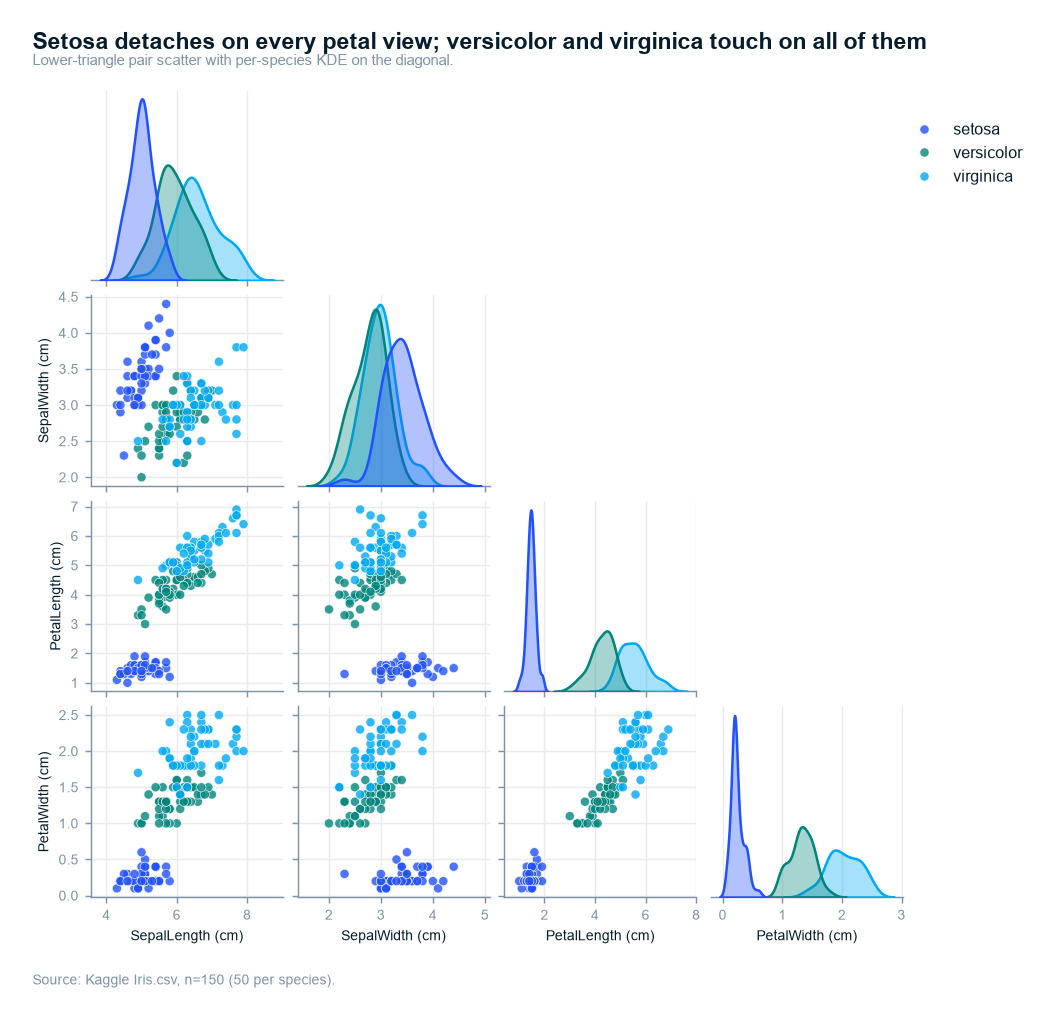

In [9]:
g = sns.pairplot(df[MEASUREMENTS + ["species"]], hue="species",
                 palette={SPECIES_SHORT[k]: v for k, v in SPECIES_COLOR.items()},
                 hue_order=["setosa", "versicolor", "virginica"],
                 diag_kind="kde", plot_kws=dict(s=26, alpha=.80, edgecolor="white", linewidth=.4),
                 diag_kws=dict(fill=True, alpha=.35, linewidth=1.4), height=1.72, corner=True)
g.figure.suptitle("Setosa detaches on every petal view; versicolor and virginica touch on all of them",
                  x=0.005, y=1.045, ha="left", fontsize=12.5, fontweight="bold", color=NAVY)
g.figure.text(0.005, 1.008, "Lower-triangle pair scatter with per-species KDE on the diagonal.",
              ha="left", fontsize=8.5, color=SLATE)
g.figure.text(0.005, -0.02, "Source: Kaggle Iris.csv, n=150 (50 per species).",
              ha="left", fontsize=7.5, color=SLATE)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=7.5)
        ax.set_xlabel(ax.get_xlabel().replace("Cm", " (cm)"), fontsize=8)
        ax.set_ylabel(ax.get_ylabel().replace("Cm", " (cm)"), fontsize=8)
sns.move_legend(g, "upper right", bbox_to_anchor=(.98, .96), frameon=False, title=None, fontsize=9)
save_fig(g.figure, "ex05_pairplot")
plt.show()

**So What:** the petal-length × petal-width panel is the tightest structure in the file — two dense,
nearly-touching clouds and one detached island — but the versicolor and virginica clouds **touch on
every panel**, including every two-feature combination. No pair of axes opens a gap that a single
axis did not already open.

**Implication:** there is no hidden diagonal for a multivariate model to exploit. Whatever a
four-feature model gains over a one-feature model will come from nudging the boundary through a
handful of contested specimens, not from finding a new separating direction. That is a testable
prediction, and Notebook 05 tests it.

## 3.5 Correlation — `Id` excluded, and this time for a stated reason

`DOCS/Iris_Dataset_Analysis.md` §5 warns that running correlations on `Id` would be *"incorrect...
it's a row identifier, not a measurement."* The exclusion is right; the stated reason is not the
real one. `Id` is excluded here because it is a **species label in disguise** (§2.4) — its
rank correlation with the petal features is 0.87–0.88, and putting it in the matrix would not be
meaningless, it would be circular.

saved reports\figures\ex06_correlation.png


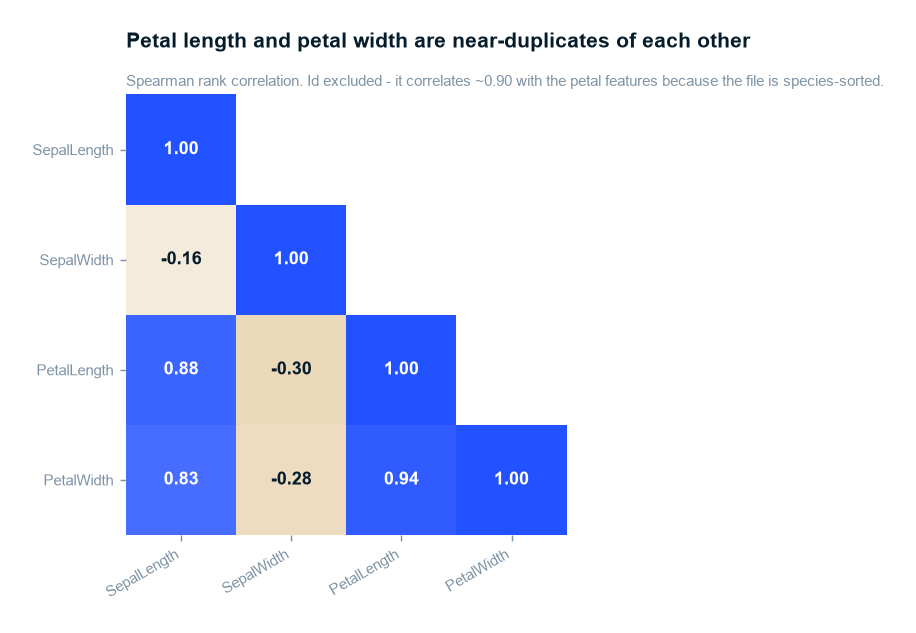

Spearman correlation of the quarantined Id column with each measurement:
SepalLengthCm    0.734
SepalWidthCm    -0.412
PetalLengthCm    0.868
PetalWidthCm     0.879


In [10]:
corr = df[MEASUREMENTS].corr(method="spearman")
id_corr = df[["Id"] + MEASUREMENTS].corr(method="spearman").loc["Id", MEASUREMENTS]

fig, ax = plt.subplots(figsize=(6.0, 4.4))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = mpl.colors.LinearSegmentedColormap.from_list("mck2", [AMBER, "#ffffff", BLUE])
im = ax.imshow(np.where(mask, np.nan, corr.to_numpy()), cmap=cmap, vmin=-1, vmax=1)
for i in range(4):
    for j in range(4):
        if not mask[i, j]:
            v = corr.to_numpy()[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(v) > .62 else NAVY, fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels([c[:-2] for c in MEASUREMENTS], rotation=30, ha="right", fontsize=8.5)
ax.set_yticks(range(4)); ax.set_yticklabels([c[:-2] for c in MEASUREMENTS], fontsize=8.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
action_title(ax, "Petal length and petal width are near-duplicates of each other",
             "Spearman rank correlation. Id excluded - it correlates ~0.90 with the petal features "
             "because the file is species-sorted.")
save_fig(fig, "ex06_correlation")
plt.show()

print("Spearman correlation of the quarantined Id column with each measurement:")
print(id_corr.round(3).to_string())

**So What:** `PetalLengthCm` and `PetalWidthCm` correlate at **ρ = 0.94**, the strongest pair in the
file. They are very close to the same measurement taken twice.

**Implication:** the four "independent predictors" are really about **two** pieces of information —
a petal-size axis and a weaker sepal-shape axis. This is the mechanism behind the parsimony result
the plan predicts: if the two petal columns are near-duplicates, dropping one should cost almost
nothing, and a one-feature model should land within noise of the four-feature model. Notebook 05
measures exactly that.

## 3.6 Ghost deck — revised after seeing the data

STRUCTURE.md §3 requires the storyboard to be updated once EDA has run. Three changes:

| Ghost deck (Stage 0) | Status after EDA | Change |
|---|---|---|
| EX 3 — setosa's petals leave a gap | **Confirmed and sharpened** | The gap is quantifiable: a 1.1 cm corridor on petal length that no specimen occupies. Exhibit now annotates it. |
| EX 4 — difficulty is one cell | **Confirmed** | versicolor/virginica best separation 0.84 vs 1.00 for setosa. Exhibit boxes the hard column. |
| EX 5 — one measurement does most of the job | **Promoted from hypothesis to prediction** | Petal ρ = 0.94 means the two petal columns are near-duplicates, so the parsimony result now has a *mechanism*, not just an expectation. |

Nothing was added or cut. One thing was **not** found, and its absence is a result: no two-feature
combination separates versicolor from virginica better than `PetalWidthCm` alone. That is recorded
here so Notebook 05's parsimony finding reads as a confirmed prediction rather than a lucky
discovery.

No data issues surfaced that require looping back to Stage 2.

In [11]:
import json

KEY["petal_length_width_spearman"] = float(corr.loc["PetalLengthCm", "PetalWidthCm"])
KEY["id_petal_length_spearman"] = float(id_corr["PetalLengthCm"])
KEY["n_specimens"] = int(len(df))
KEY["n_per_species"] = int(df[TARGET].value_counts().iloc[0])
KEY["petal_length_corridor_cm"] = float(
    df.loc[df.species == "versicolor", "PetalLengthCm"].min()
    - df.loc[df.species == "setosa", "PetalLengthCm"].max())

(REPORTS / "_key_figures.json").write_text(json.dumps(KEY, indent=2))
print(json.dumps(KEY, indent=2))

{
  "majority_baseline": 0.3333333333333333,
  "n_disjoint_combinations": 4,
  "separation_setosa_mean_petal": 1.0,
  "separation_versicolor_virginica_best": 0.836,
  "separation_versicolor_virginica_best_feature": "PetalWidthCm",
  "separation_sepalwidth_vv": 0.195,
  "petal_length_width_spearman": 0.9360033509355781,
  "id_petal_length_spearman": 0.8684982456933065,
  "n_specimens": 150,
  "n_per_species": 50,
  "petal_length_corridor_cm": 1.1
}


## Stage 3 — Gate Checklist

- [x] **Automated profiling reviewed** — manual describe/skew/kurtosis panel (§3.1);
      `ydata-profiling` deliberately not a dependency on a 4-column file, decision documented
- [x] **Each Stage 0 hypothesis has a corresponding analysis** — Branch B (sepal) §3.1–3.3,
      Branch C (petal) §3.2–3.5, Branch A (instrument) carried in from Notebook 02
- [x] **Key distributions and relationships visualised and annotated** — 4 exhibits, each with a
      written So What and Implication
- [x] **All chart titles are Action Titles** — every title states the insight, flush-left per
      `DOCS/DESIGN.md` §1.3
- [x] **Every finding has a documented So What and Implication** — no chart ships without one
- [x] **Ghost deck updated** (§3.6) — two exhibits confirmed and sharpened, one hypothesis promoted
      to a mechanism-backed prediction, one null result recorded
- [x] **Data issues logged** — none new; the Stage 2 defects need no re-treatment
- [x] **Preliminary findings documented** — `_separation.csv`, `_key_figures.json`

**What EDA established:** setosa is separated from the other two species by an empty corridor
(separation 1.00), versicolor and virginica remain partly mixed on every feature (best 0.84),
and the two petal columns are 0.94-correlated near-duplicates. The classification problem is one
trivial problem plus one hard one, and the hard one is decided on a fraction of the file.

**Next:** `04_diagnostic.ipynb` — Path A, Stage 5a: effect sizes with confidence intervals,
formal separability tests, and Fisher's own discriminant analysis.